# Hospital Readmission Risk Prediction Using MLP



## CBIM Canvas

| CBIM Element | Answer |
|---|---|
| **Situation (S)** | The hospital sends many diabetic patients home every day. Right now, doctors and nurses decide by experience who needs extra care after going home. |
| **Complication (C)** | About 11% of patients come back to the hospital within 30 days. **Hospital:** this costs money and fills beds. **Staff:** they cannot follow up with every patient, so some high-risk patients are missed. **Patients:** they go home without enough support and may come back sicker. |
| **Question (Q)** | At the time of discharge, which patients are at **high risk** of coming back within 30 days? The hospital will give these patients extra care first: a follow-up phone call, an early doctor appointment and better discharge planning. |
| **SSOT** | The single source of truth is the file `diabetic_data.csv` (UCI Diabetes 130-US Hospitals dataset, 101,766 patient visits). The decision column is `readmitted`. It tells if the patient came back to the hospital: `<30` = within 30 days, `>30` = after 30 days, `NO` = did not come back. We change it to **1 = came back within 30 days** and **0 = did not come back within 30 days**. |
| **Success definition** | The main metric is **Recall**: how many of the patients who really came back did the model catch? Our goal is **Recall of at least 60%** on the test data. ROC-AUC should also be clearly better than 0.5 (random guessing). We do not use Accuracy as the main metric, because a model that always says "No" already gets about 91% accuracy but catches no one. |
| **Primary stakeholder** | **The hospital's discharge planning manager**, who decides which patients get extra follow-up care. Others affected: **patients and families** (they get or miss extra care), **doctors and nurses** (their workload changes) and **hospital management** (costs and bed use). |


##  Data Understanding

### Import Libraries

In [1]:
# Import required libraries

import zipfile
import io

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import Precision, Recall, AUC

import warnings
warnings.filterwarnings("ignore")

# Set random seeds so results can be repeated
np.random.seed(42)
tf.random.set_seed(42)

sns.set_style("whitegrid")

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.22.0-rc0
Libraries imported successfully!


### Load Dataset

In [2]:
# Load the main dataset from the zip file

zip_path = "diabetes+130-us+hospitals+for+years+1999-2008.zip"

with zipfile.ZipFile(zip_path) as z:
    print("Files inside the zip:", z.namelist())

    with z.open("diabetic_data.csv") as file:
        df = pd.read_csv(file, na_values="?", keep_default_na=False)

print("\nDataset loaded successfully!")

Files inside the zip: ['diabetic_data.csv', 'IDS_mapping.csv']

Dataset loaded successfully!


### Display the Dataset

In [3]:
# Display first 5 rows

df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [4]:
# Display last 5 rows

df.tail()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
101761,443847548,100162476,AfricanAmerican,Male,[70-80),NaN,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),NaN,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),NaN,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),NaN,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO
101765,443867222,175429310,Caucasian,Male,[70-80),NaN,1,1,7,6,...,No,No,No,No,No,No,No,No,No,NO


In [5]:
# Display 5 random rows

df.sample(5, random_state=42)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
35956,110939484,19274094,Caucasian,Female,[70-80),NaN,1,1,6,11,...,No,Steady,No,No,No,No,No,No,Yes,NO
60927,170328306,65634327,Caucasian,Male,[50-60),NaN,1,1,1,1,...,No,No,No,No,No,No,No,No,Yes,NO
79920,245688426,100657359,Caucasian,Female,[60-70),NaN,3,6,1,4,...,No,No,No,No,No,No,No,No,Yes,NO
50078,150826224,83144448,Caucasian,Male,[30-40),NaN,2,1,1,12,...,No,No,No,No,No,No,No,No,Yes,>30
44080,135993852,65234214,AfricanAmerican,Female,[60-70),NaN,1,2,7,1,...,No,No,No,No,No,No,No,No,Yes,<30


### Check Dataset Shape

In [6]:
# Check the number of rows and columns

print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (101766, 50)
Number of rows: 101766
Number of columns: 50


### Dataset Information

In [7]:
# Display column names, data types and non-null counts

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

### Statistical Summary

In [8]:
# Statistical summary of numerical columns

df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [9]:
# Statistical summary of categorical columns

df.describe(include="object")

,race,gender,age,weight,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,99493,101766,101766,3197,61510,51817,101745,101408,100343,101766,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,5,3,10,9,17,72,716,748,789,4,...,1,4,4,2,2,2,2,2,2,3
top,Caucasian,Female,[70-80),[75-100),MC,InternalMedicine,428,276,250,None,...,No,No,No,No,No,No,No,No,Yes,NO
freq,76099,54708,26068,1336,32439,14635,6862,6752,11555,96420,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864


### Check Missing Values

In [10]:
# Count missing values and their percentages

missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage.round(2)
})

missing_table = missing_table[missing_table["Missing Count"] > 0]

missing_table = missing_table.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_table

,Missing Count,Missing Percentage
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


### Visualize Missing Values

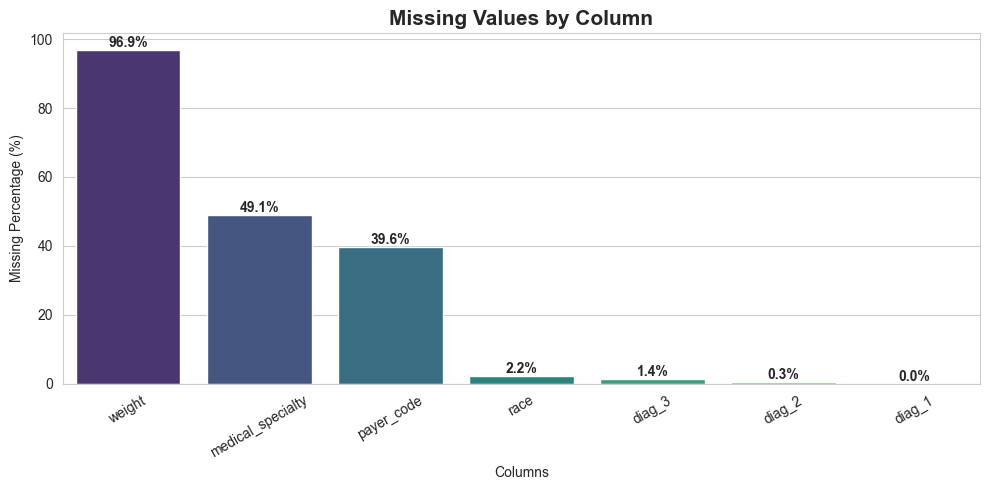

In [11]:
# Plot missing-value percentages

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=missing_table.index,
    y=missing_table["Missing Percentage"],
    hue=missing_table.index,
    palette="viridis",
    legend=False
)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Missing Values by Column", fontsize=15, fontweight="bold")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Observation on Missing Values

| Column | Missing | Decision |
|---|---|---|
| `weight` | ~97% | **Drop**: almost no information is available |
| `medical_specialty` | ~49% | Keep and fill with `"Unknown"`: the specialty may still be useful |
| `payer_code` | ~40% | Keep and fill with `"Unknown"` |
| `race` | ~2% | Fill with the most frequent value (on training data only) |
| `diag_1`, `diag_2`, `diag_3` | < 2% | Fill with the most frequent value (on training data only) |

For `medical_specialty` and `payer_code`, the fact that the value is missing could itself carry information, so we use a separate `"Unknown"` category instead of guessing a value.

### Check Duplicate Records

In [12]:
# Count fully duplicated rows

print("Number of duplicate rows:", df.duplicated().sum())

# Count patients who appear more than once

print("Unique encounters:", df["encounter_id"].nunique())
print("Unique patients:", df["patient_nbr"].nunique())

Number of duplicate rows: 0
Unique encounters: 101766
Unique patients: 71518


### Understand the Target Variable

In [13]:
# Check the original target values

print(df["readmitted"].value_counts())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


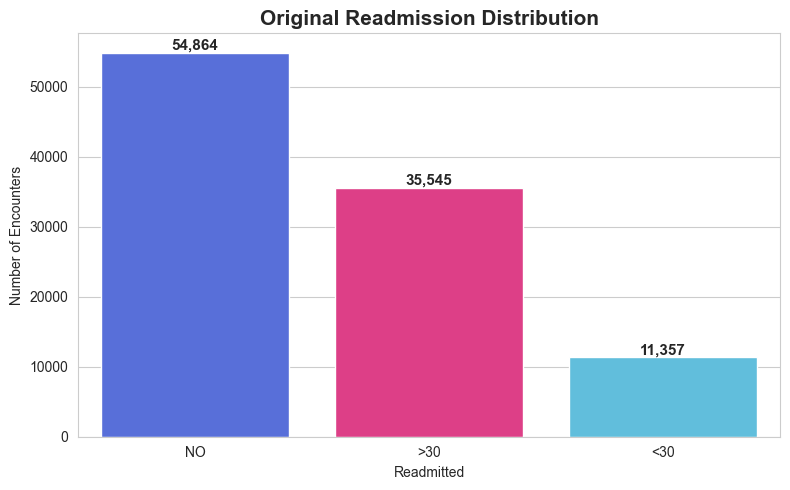

In [14]:
# Plot the original target distribution

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="readmitted",
    hue="readmitted",
    palette=["#4361EE", "#F72585", "#4CC9F0"],
    legend=False
)

for bar in ax.patches:
    ax.annotate(
        format(int(bar.get_height()), ","),
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title("Original Readmission Distribution", fontsize=15, fontweight="bold")
plt.xlabel("Readmitted")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

## Class Imbalance Analysis

Class imbalance occurs when one target class contains significantly more records than another.

A model may achieve high accuracy while failing to identify the smaller group. Here, the smaller group (patients readmitted within 30 days) is exactly the group we care about.

In [15]:
# Create a temporary binary target for class imbalance analysis

y_temp = (df["readmitted"] == "<30").astype(int)

print("Class Counts:")
print(y_temp.value_counts())

print("\nClass Percentages:")
print((y_temp.value_counts(normalize=True) * 100).round(2))

Class Counts:
readmitted
0    90409
1    11357
Name: count, dtype: int64

Class Percentages:
readmitted
0    88.84
1    11.16
Name: proportion, dtype: float64


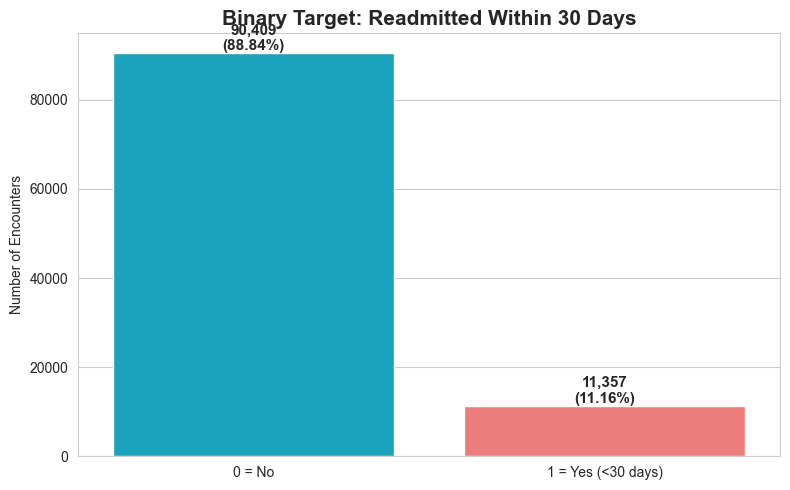

In [16]:
# Plot the binary target distribution

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=y_temp,
    hue=y_temp,
    palette=["#00B4D8", "#FF6B6B"],
    legend=False
)

total = len(y_temp)

for bar in ax.patches:
    count = int(bar.get_height())
    ax.annotate(
        f"{count:,}\n({count / total * 100:.2f}%)",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title("Binary Target: Readmitted Within 30 Days", fontsize=15, fontweight="bold")
plt.xticks([0, 1], ["0 = No", "1 = Yes (<30 days)"])
plt.xlabel("")
plt.ylabel("Number of Encounters")
plt.tight_layout()
plt.show()

### Observation on Class Imbalance

- Only about **11%** of encounters are readmitted within 30 days; about **89%** are not.
- A model that always predicts "No" would get ~89% accuracy but would **catch zero high-risk patients**.
- Therefore:
  - Accuracy alone is **not** a good metric here. We will focus on **Recall, Precision, F1-score and ROC-AUC**.
  - We will use **class weights** during training so the model pays more attention to the minority class.
  - We will use **stratified splitting** so every dataset has the same class proportions.

##  Exploratory Data Analysis


In [17]:
# Create a copy of the data with the binary target for analysis

eda_df = df.copy()
eda_df["readmit_30"] = (eda_df["readmitted"] == "<30").astype(int)

print("Overall 30-day readmission rate:", round(eda_df["readmit_30"].mean() * 100, 2), "%")

Overall 30-day readmission rate: 11.16 %


### Readmission Rate by Age Group

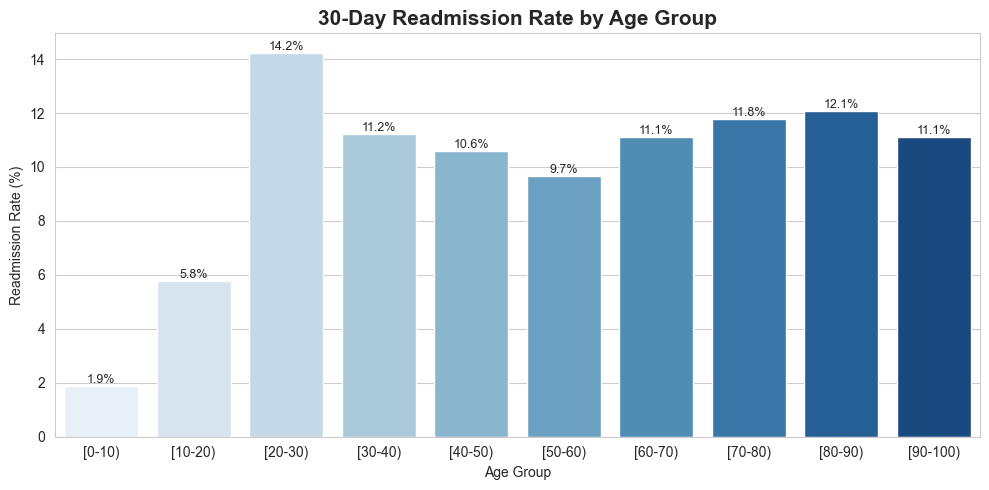

In [18]:
# Readmission rate (%) for each age group

age_rate = eda_df.groupby("age")["readmit_30"].mean() * 100

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=age_rate.index,
    y=age_rate.values,
    hue=age_rate.index,
    palette="Blues",
    legend=False
)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title("30-Day Readmission Rate by Age Group", fontsize=15, fontweight="bold")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")
plt.tight_layout()
plt.show()

### Readmission Rate by Number of Previous Inpatient Visits

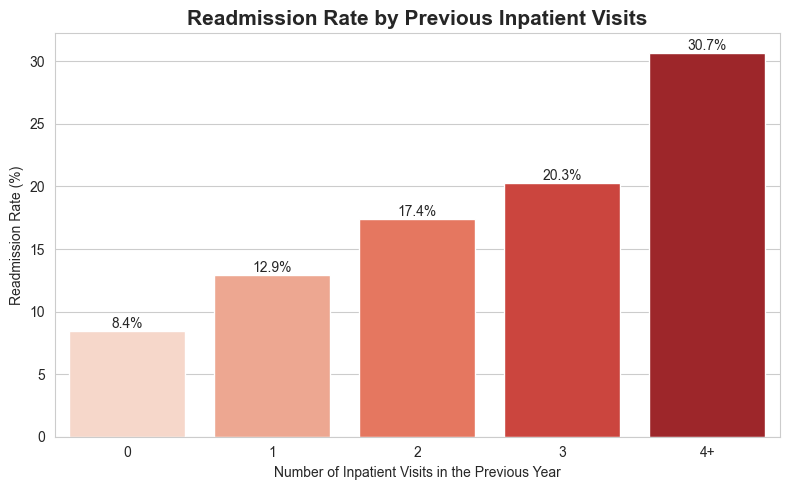

In [19]:
# Group number_inpatient into simple bins

eda_df["inpatient_group"] = pd.cut(
    eda_df["number_inpatient"],
    bins=[-1, 0, 1, 2, 3, 100],
    labels=["0", "1", "2", "3", "4+"]
)

inpatient_rate = eda_df.groupby("inpatient_group", observed=True)["readmit_30"].mean() * 100

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=inpatient_rate.index,
    y=inpatient_rate.values,
    hue=inpatient_rate.index,
    palette="Reds",
    legend=False
)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Readmission Rate by Previous Inpatient Visits", fontsize=15, fontweight="bold")
plt.xlabel("Number of Inpatient Visits in the Previous Year")
plt.ylabel("Readmission Rate (%)")
plt.tight_layout()
plt.show()

### Readmission Rate by Time in Hospital

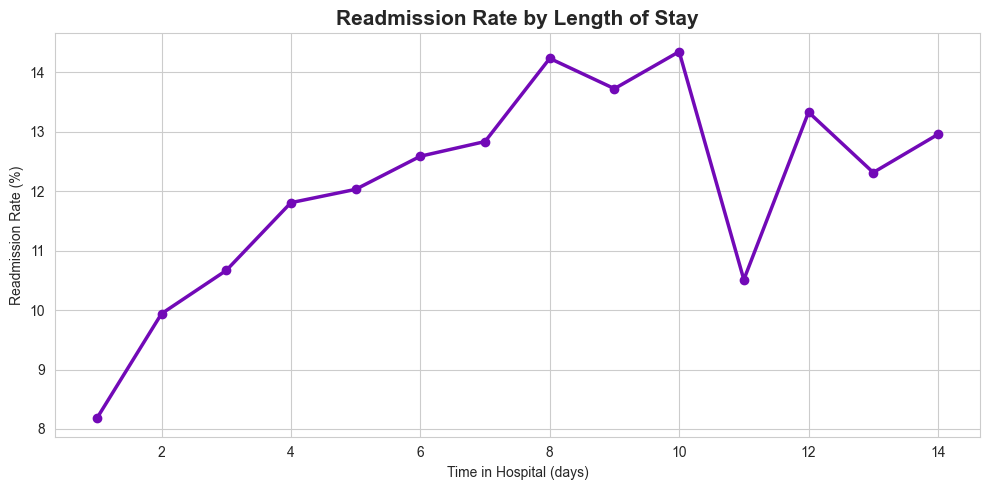

In [20]:
# Readmission rate (%) for each length of stay

stay_rate = eda_df.groupby("time_in_hospital")["readmit_30"].mean() * 100

plt.figure(figsize=(10, 5))

plt.plot(stay_rate.index, stay_rate.values, marker="o", color="#7209B7", linewidth=2.5)

plt.title("Readmission Rate by Length of Stay", fontsize=15, fontweight="bold")
plt.xlabel("Time in Hospital (days)")
plt.ylabel("Readmission Rate (%)")
plt.tight_layout()
plt.show()

### Correlation of Numerical Features with Readmission

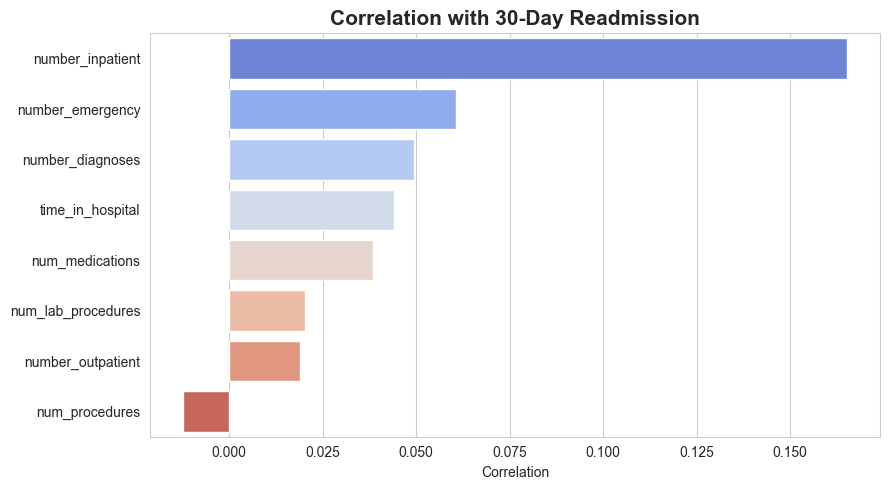

number_inpatient      0.1651
number_emergency      0.0607
number_diagnoses      0.0495
time_in_hospital      0.0442
num_medications       0.0384
num_lab_procedures    0.0204
number_outpatient     0.0189
num_procedures       -0.0122
Name: readmit_30, dtype: float64


In [21]:
# Correlation between each numerical feature and the target

numeric_features = [
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses"
]

correlation = eda_df[numeric_features + ["readmit_30"]].corr()["readmit_30"].drop("readmit_30")
correlation = correlation.sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=correlation.values,
    y=correlation.index,
    hue=correlation.index,
    palette="coolwarm",
    legend=False
)

plt.title("Correlation with 30-Day Readmission", fontsize=15, fontweight="bold")
plt.xlabel("Correlation")
plt.ylabel("")
plt.tight_layout()
plt.show()

print(correlation.round(4))

### EDA Observations

- **Previous inpatient visits** are the strongest signal. Patients who were admitted more often in the past year come back much more often.
- **Emergency visits** and **number of diagnoses** also go up with readmission.
- **Longer hospital stays** show a slightly higher readmission rate.
- All correlations are **weak** (below 0.2). No single feature can predict readmission alone, so we use an MLP that can combine many features.
- Patients who **died or went to hospice** can never come back. We remove them in Data Preparation.


##  Data Preparation

###  Convert Target Variable

- `1` → Readmitted within 30 days (`<30`)
- `0` → Not readmitted within 30 days (`>30` or `NO`)

In [22]:
# Convert readmitted into a binary target

df["readmitted"] = (df["readmitted"] == "<30").astype(int)

print(df["readmitted"].value_counts())

readmitted
0    90409
1    11357
Name: count, dtype: int64


###  Remove Patients Who Cannot Be Readmitted

Some patients **died** or were **sent to hospice** at discharge (`discharge_disposition_id` = 11, 13, 14, 19, 20, 21).

These patients cannot (or are not expected to) return to the hospital, so they would confuse the model. We remove them.

In [23]:
# Discharge codes for expired or hospice patients

expired_or_hospice = [11, 13, 14, 19, 20, 21]

print("Rows before:", len(df))

df = df[~df["discharge_disposition_id"].isin(expired_or_hospice)]

print("Rows after:", len(df))

Rows before: 101766
Rows after: 99343


###  Data Leakage: Keep One Encounter per Patient

**Data leakage** means using information during training that would not be available in a real situation, which makes the model look better than it really is.

**Problem:** The data has 101,766 visits but only 71,518 unique patients, so many patients appear more than once. If one visit of a patient is in training and another visit of the same patient is in testing, the model can simply "remember" that patient.

**Solution:** We keep only the **first visit** of each patient. Now every patient appears only once, in only one of train, validation or test.

We also use **only information that is known at the time of discharge** (patient details, diagnoses, tests, medicines, previous visits). Nothing from after discharge is used.


In [24]:
# Sort by encounter_id (smaller id = earlier visit) and keep the first visit per patient

df = df.sort_values("encounter_id")
df = df.drop_duplicates(subset="patient_nbr", keep="first")

print("Rows after keeping one encounter per patient:", len(df))
print("Unique patients:", df["patient_nbr"].nunique())

print("\nTarget distribution after cleaning:")
print((df["readmitted"].value_counts(normalize=True) * 100).round(2))

Rows after keeping one encounter per patient: 69990
Unique patients: 69990

Target distribution after cleaning:
readmitted
0    91.02
1     8.98
Name: proportion, dtype: float64


###  Handle Missing Values

Following the decisions in **Observation on Missing Values**:
- Drop `weight` (~97% missing).
- Fill `medical_specialty` and `payer_code` with `"Unknown"`.
- The remaining small gaps (`race`, `diag_1/2/3`) are filled later using the training data only.

In [25]:
# Drop weight column

df = df.drop(columns=["weight"])

# Fill high-missing categorical columns with "Unknown"

df["medical_specialty"] = df["medical_specialty"].fillna("Unknown")
df["payer_code"] = df["payer_code"].fillna("Unknown")

# Check remaining missing values

df.isnull().sum()[df.isnull().sum() > 0]

race      1919
diag_1      10
diag_2     293
diag_3    1224
dtype: int64

###  Remove Columns With Only One Value

Some medication columns have the same value for every patient. A column that never changes cannot help the model, so we remove it.

In [26]:
# Find columns with only one unique value

single_value_columns = [col for col in df.columns if df[col].nunique() <= 1]

print("Columns with only one value:", single_value_columns)

df = df.drop(columns=single_value_columns)

Columns with only one value: ['examide', 'citoglipton', 'glimepiride-pioglitazone']


In [27]:
# Convert ID codes into categorical (text) columns

id_columns = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]

df[id_columns] = df[id_columns].astype(str)

df[id_columns].dtypes

admission_type_id           object
discharge_disposition_id    object
admission_source_id         object
dtype: object

###  Group Diagnosis Codes


In [28]:
# Group an ICD-9 code into a disease category

def group_diagnosis(code):
    if pd.isnull(code):
        return np.nan

    code = str(code)

    if code.startswith("V") or code.startswith("E"):
        return "Other"

    number = float(code)

    if 390 <= number <= 459 or number == 785:
        return "Circulatory"
    elif 460 <= number <= 519 or number == 786:
        return "Respiratory"
    elif 520 <= number <= 579 or number == 787:
        return "Digestive"
    elif int(number) == 250:
        return "Diabetes"
    elif 800 <= number <= 999:
        return "Injury"
    elif 710 <= number <= 739:
        return "Musculoskeletal"
    elif 580 <= number <= 629 or number == 788:
        return "Genitourinary"
    elif 140 <= number <= 239:
        return "Neoplasms"
    else:
        return "Other"


for col in ["diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].apply(group_diagnosis)

df["diag_1"].value_counts()

diag_1
Circulatory        21390
Other              12124
Respiratory         9491
Digestive           6488
Diabetes            5748
Injury              4696
Musculoskeletal     4064
Genitourinary       3441
Neoplasms           2538
Name: count, dtype: int64

### Separate Features and Target

- **X (Features):** Input variables used to make predictions.
- **y (Target):** `readmitted`.

We remove the identifier columns `encounter_id` and `patient_nbr` from the features. We keep `patient_nbr` separately so we can build the patient-level report at the end.

In [29]:
# Keep patient IDs for the final report

patient_ids = df["patient_nbr"]

# Separate input features and target

X = df.drop(columns=["readmitted", "encounter_id", "patient_nbr"])
y = df["readmitted"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (69990, 43)
Target shape: (69990,)


In [30]:
# Identify numerical and categorical columns

numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()

print("Number of numerical columns:", len(numerical_columns))
print("Number of categorical columns:", len(categorical_columns))

print("\nNumerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Number of numerical columns: 8
Number of categorical columns: 35

Numerical columns:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical columns:
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


## Data Splitting

- Training data (70%): used to train the model.
- Validation data (15%): used to tune and compare models.
- Testing data (15%): used only once, to evaluate the final model.

We use `stratify` so all three sets keep the same percentage of readmitted patients.

In [31]:
# First split: 70% training, 30% temporary

X_train, X_temp, y_train, y_temp, id_train, id_temp = train_test_split(
    X, y, patient_ids,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: the 30% is divided equally into validation and testing

X_val, X_test, y_val, y_test, id_val, id_test = train_test_split(
    X_temp, y_temp, id_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training data:  ", X_train.shape, y_train.shape)
print("Validation data:", X_val.shape, y_val.shape)
print("Testing data:   ", X_test.shape, y_test.shape)

Training data:   (48993, 43) (48993,)
Validation data: (10498, 43) (10498,)
Testing data:    (10499, 43) (10499,)


In [32]:
# Check class proportions in each set

split_check = pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Validation (%)": y_val.value_counts(normalize=True) * 100,
    "Test (%)": y_test.value_counts(normalize=True) * 100
}).round(2)

split_check

,Train (%),Validation (%),Test (%)
readmitted,,,
0,91.02,91.03,91.02
1,8.98,8.97,8.98


###  Missing-Value Imputation

- Median for numerical columns.
- Most frequent value for categorical columns.

The imputers are fitted **only on training data** and then applied to validation and test data, to prevent data leakage.

In [33]:
# Create imputers

numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

# Fit on training data, then transform all sets

X_train_num = numeric_imputer.fit_transform(X_train[numerical_columns])
X_val_num = numeric_imputer.transform(X_val[numerical_columns])
X_test_num = numeric_imputer.transform(X_test[numerical_columns])

X_train_cat = categorical_imputer.fit_transform(X_train[categorical_columns])
X_val_cat = categorical_imputer.transform(X_val[categorical_columns])
X_test_cat = categorical_imputer.transform(X_test[categorical_columns])

print("Missing values in training data after imputation:",
      pd.isnull(X_train_cat).sum() + np.isnan(X_train_num).sum())

Missing values in training data after imputation: 0


###  One-Hot Encoding


In [34]:
# Create One-Hot Encoder

encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=0.01,
    sparse_output=False
)

# Fit only on training data

X_train_encoded = encoder.fit_transform(X_train_cat)
X_val_encoded = encoder.transform(X_val_cat)
X_test_encoded = encoder.transform(X_test_cat)

print("Encoded training shape:", X_train_encoded.shape)

Encoded training shape: (48993, 147)


###  Feature Scaling


In [35]:
# Create StandardScaler and fit only on training data

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_num)
X_val_scaled = scaler.transform(X_val_num)
X_test_scaled = scaler.transform(X_test_num)

print("StandardScaler applied successfully!")

StandardScaler applied successfully!


### Combine Preprocessed Features

In [36]:
# Combine scaled numerical and encoded categorical features

X_train_final = np.concatenate([X_train_scaled, X_train_encoded], axis=1).astype("float32")
X_val_final = np.concatenate([X_val_scaled, X_val_encoded], axis=1).astype("float32")
X_test_final = np.concatenate([X_test_scaled, X_test_encoded], axis=1).astype("float32")

y_train_final = y_train.to_numpy()
y_val_final = y_val.to_numpy()
y_test_final = y_test.to_numpy()

print("Final training data:  ", X_train_final.shape)
print("Final validation data:", X_val_final.shape)
print("Final testing data:   ", X_test_final.shape)

Final training data:   (48993, 155)
Final validation data: (10498, 155)
Final testing data:    (10499, 155)


##  MLP Architecture Design

A Multi-Layer Perceptron (MLP) is an Artificial Neural Network made of fully connected (Dense) layers.

Our model consists of:

| Layer | Details | Purpose |
|---|---|---|
| Input layer | One input per preprocessed feature | Receives patient data |
| Hidden layer 1 | Dense, 64 neurons, ReLU | Learns basic patterns |
| Dropout | 30% | Reduces overfitting |
| Hidden layer 2 | Dense, 32 neurons, ReLU | Learns combinations of patterns |
| Dropout | 30% | Reduces overfitting |
| Hidden layer 3 | Dense, 16 neurons, ReLU | Learns higher-level patterns |
| Output layer | Dense, 1 neuron, Sigmoid | Outputs the probability of readmission (0 to 1) |

### Key TensorFlow / Keras Concepts Used

| Concept | Explanation |
|---|---|
| **Sequential API** | Builds the model as a simple stack of layers, one after another. |
| **Dense layer** | Every neuron is connected to every neuron in the previous layer. |
| **ReLU activation** | `max(0, x)`. Adds non-linearity so the model can learn complex patterns, and trains fast. |
| **Sigmoid activation** | Squashes the output between 0 and 1, so it can be read as a probability. |
| **Dropout** | Randomly switches off some neurons during training, so the model does not depend too much on any single neuron (reduces overfitting). |
| **Adam optimizer** | Updates the weights using an adaptive learning rate. Works well with default settings. |
| **Binary Crossentropy** | The standard loss function for two-class problems with a Sigmoid output. |
| **Epoch** | One full pass through the entire training dataset. |
| **Batch size** | Number of samples the model sees before updating its weights once. |
| **EarlyStopping** | Stops training when validation loss stops improving, and restores the best weights. |
| **Class weights** | Gives more importance to the minority class (readmitted patients) in the loss. |

### Build the MLP Model

We write a small function to build the model, so we can create a fresh model for each training experiment.

In [37]:
# Function to build the MLP model

def build_mlp_model(number_of_features):
    model = Sequential([
        Input(shape=(number_of_features,)),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(32, activation="relu"),
        Dropout(0.3),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            Precision(name="precision"),
            Recall(name="recall"),
            AUC(name="auc")
        ]
    )

    return model


number_of_features = X_train_final.shape[1]

model = build_mlp_model(number_of_features)

print("MLP model created and compiled successfully!")

MLP model created and compiled successfully!


### Display Model Architecture

The model summary shows the layers, output shapes and number of trainable parameters.

In [38]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         9,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,609 (49.25 KB)

 Trainable params: 12,609 (49.25 KB)

 Non-trainable params: 0 (0.00 B)

### Compilation Details

- **Optimizer:** Adam (learning rate = 0.001).
- **Loss Function:** Binary Crossentropy.
- **Metrics:** Accuracy, Precision, Recall and AUC.

## Model Training

### Handle Class Imbalance with Class Weights

`compute_class_weight("balanced")` gives each class a weight that is inversely proportional to its size.

The minority class (readmitted) gets a **higher weight**, so mistakes on readmitted patients are penalised more during training.

In [39]:
# Calculate class weights using training data only

classes = np.unique(y_train_final)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_final
)

class_weights = {int(c): float(w) for c, w in zip(classes, weights)}

print("Class weight for class 0 (not readmitted):", round(class_weights[0], 3))
print("Class weight for class 1 (readmitted):    ", round(class_weights[1], 3))

Class weight for class 0 (not readmitted): 0.549
Class weight for class 1 (readmitted):     5.567


### Set Callbacks

- `monitor="val_loss"`: watches the validation loss.
- `patience=5`: waits 5 epochs without improvement before stopping.
- `restore_best_weights=True`: goes back to the weights of the best epoch.

In [40]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

print("EarlyStopping callback created successfully!")

EarlyStopping callback created successfully!


### Train the Baseline Model

We first train the model with 30 epochs and a batch size of 256.

In [41]:
# Train the baseline MLP model

history = model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val_final, y_val_final),
    epochs=30,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5518 - auc: 0.5318 - loss: 0.6984 - precision: 0.0987 - recall: 0.4909 - val_accuracy: 0.4649 - val_auc: 0.6094 - val_loss: 0.7179 - val_precision: 0.1098 - val_recall: 0.6985
Epoch 2/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5979 - auc: 0.5843 - loss: 0.6812 - precision: 0.1147 - recall: 0.5173 - val_accuracy: 0.5419 - val_auc: 0.6397 - val_loss: 0.7063 - val_precision: 0.1211 - val_recall: 0.6561
Epoch 3/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6045 - auc: 0.6140 - loss: 0.6726 - precision: 0.1219 - recall: 0.5489 - val_accuracy: 0.5731 - val_auc: 0.6463 - val_loss: 0.6969 - val_precision: 0.1264 - val_recall: 0.6359
Epoch 4/30
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5919 - auc: 0.6291 - loss: 0.6667 - precision: 0.1255 - recall: 0.5941 - val_accuracy: 0.5842 - val_auc: 0.6540 - val_loss: 0.6853 - val_precision: 0.1298 - val_recall: 0.6369
Epoch 5/30
192/192 ━━━━━━━━━━━━━

### Plot Training History

- **Loss** shows prediction error.
- **AUC** shows how well the model separates the two classes.

We plot AUC instead of accuracy because accuracy is misleading on imbalanced data.

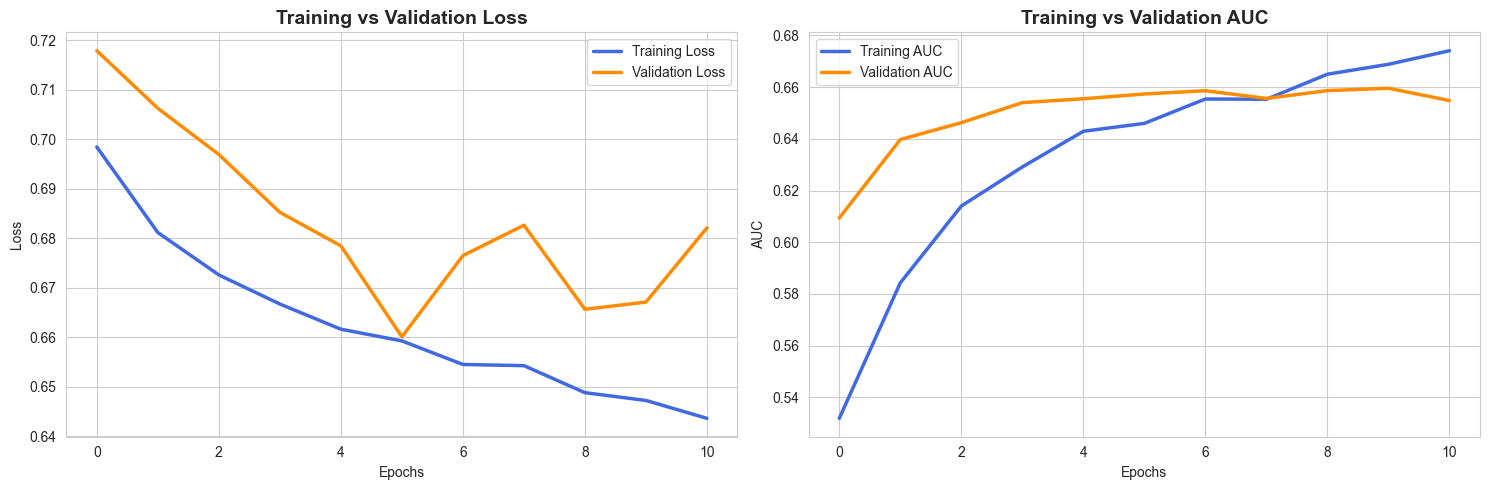

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss graph
axes[0].plot(history.history["loss"], label="Training Loss", color="royalblue", linewidth=2.5)
axes[0].plot(history.history["val_loss"], label="Validation Loss", color="darkorange", linewidth=2.5)
axes[0].set_title("Training vs Validation Loss", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].legend()

# AUC graph
axes[1].plot(history.history["auc"], label="Training AUC", color="royalblue", linewidth=2.5)
axes[1].plot(history.history["val_auc"], label="Validation AUC", color="darkorange", linewidth=2.5)
axes[1].set_title("Training vs Validation AUC", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("AUC")
axes[1].legend()

plt.tight_layout()
plt.show()

### Experiment with Epochs and Batch Sizes



- A **small batch size** updates the weights more often (slower, but can learn finer details).
- A **large batch size** updates less often (faster, smoother learning).
- **More epochs** give the model more time to learn, but EarlyStopping stops training if it starts overfitting.

We train a fresh model for each combination and compare them on the **validation** data.

In [43]:
# Different training settings to compare

experiments = [
    {"epochs": 20, "batch_size": 64},
    {"epochs": 30, "batch_size": 128},
    {"epochs": 30, "batch_size": 256},
    {"epochs": 50, "batch_size": 512},
]

experiment_results = []
trained_models = []

for setting in experiments:
    tf.random.set_seed(42)

    exp_model = build_mlp_model(number_of_features)

    exp_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    exp_history = exp_model.fit(
        X_train_final,
        y_train_final,
        validation_data=(X_val_final, y_val_final),
        epochs=setting["epochs"],
        batch_size=setting["batch_size"],
        class_weight=class_weights,
        callbacks=[exp_stop],
        verbose=0
    )

    val_prob = exp_model.predict(X_val_final, verbose=0).flatten()
    val_pred = (val_prob >= 0.5).astype(int)

    experiment_results.append({
        "Max Epochs": setting["epochs"],
        "Batch Size": setting["batch_size"],
        "Epochs Trained": len(exp_history.history["loss"]),
        "Val Loss": min(exp_history.history["val_loss"]),
        "Val Recall": recall_score(y_val_final, val_pred),
        "Val Precision": precision_score(y_val_final, val_pred),
        "Val F1": f1_score(y_val_final, val_pred),
        "Val ROC-AUC": roc_auc_score(y_val_final, val_prob)
    })

    trained_models.append(exp_model)

    print(f"Finished: epochs={setting['epochs']}, batch_size={setting['batch_size']}")

experiment_df = pd.DataFrame(experiment_results).round(4)
experiment_df

Finished: epochs=20, batch_size=64
Finished: epochs=30, batch_size=128
Finished: epochs=30, batch_size=256
Finished: epochs=50, batch_size=512


,Max Epochs,Batch Size,Epochs Trained,Val Loss,Val Recall,Val Precision,Val F1,Val ROC-AUC
0,20,64,12,0.6148,0.4958,0.1523,0.2330,0.6547
1,30,128,23,0.5847,0.5180,0.1444,0.2258,0.6454
2,30,256,9,0.6327,0.5403,0.1404,0.2229,0.6535
3,50,512,48,0.5613,0.4735,0.1414,0.2177,0.6394


In [44]:
# Select the best setting based on validation ROC-AUC

best_index = experiment_df["Val ROC-AUC"].idxmax()

best_model = trained_models[best_index]
best_setting = experiment_df.loc[best_index]

print("Best setting:")
print(best_setting)

Best setting:
Max Epochs        20.0000
Batch Size        64.0000
Epochs Trained    12.0000
Val Loss           0.6148
Val Recall         0.4958
Val Precision      0.1523
Val F1             0.2330
Val ROC-AUC        0.6547
Name: 0, dtype: float64


### Observation on Training Experiments

- In all 4 runs, EarlyStopping stopped training **before** the maximum number of epochs. The model learns the useful patterns early; more epochs would only cause overfitting.
- All batch sizes give **similar** validation ROC-AUC (about 0.65 to 0.66). Batch size mainly changes training speed, not final quality.
- We pick the setting with the **highest validation ROC-AUC** as our final model.


##  Model Generalization

Model generalization means how well the model performs on **unseen** data.

We compare the training and validation performance of the final model:
- **Good generalization:** training and validation metrics are similar.
- **Overfitting:** training performance is much better than validation performance.
- **Underfitting:** both are poor.

In [45]:
# Evaluate the best model on training and validation data

train_results = best_model.evaluate(X_train_final, y_train_final, verbose=0, return_dict=True)
val_results = best_model.evaluate(X_val_final, y_val_final, verbose=0, return_dict=True)

comparison_df = pd.DataFrame({
    "Training": train_results,
    "Validation": val_results
})

comparison_df["Gap"] = comparison_df["Training"] - comparison_df["Validation"]

comparison_df.round(4)

,Training,Validation,Gap
accuracy,0.7104,0.7071,0.0033
auc,0.6908,0.6547,0.0361
loss,0.6097,0.6148,-0.0052
precision,0.1616,0.1523,0.0093
recall,0.5311,0.4958,0.0354


### Generalization Analysis

- The gap between training and validation metrics shows how much the model has memorised the training data.
- **Dropout** and **EarlyStopping** keep this gap small.
- The ROC-AUC is moderate on both sets. This is expected for this dataset: readmission depends on many factors that are not recorded (social support, medication adherence after discharge, etc.), so even published studies on this dataset report ROC-AUC values of around 0.65-0.70.

##  Model Evaluation

###  Choose the Decision Threshold

The model outputs a probability. By default, a probability of 0.5 or more means "readmitted".

But 0.5 is not always the best choice for a business problem. Because **missing a high-risk patient is costly** (see the CBIM Canvas), we want the model to catch at least **60% of the patients who are actually readmitted** (Recall ≥ 0.60).

We check several thresholds on the **validation data** and choose the **highest threshold that still gives Recall ≥ 0.60**. Choosing the highest such threshold keeps the number of false alarms as low as possible.

We choose the threshold on validation data, **not test data**, so the test result stays unbiased.

In [46]:
# Validation probabilities from the best model

val_prob = best_model.predict(X_val_final, verbose=0).flatten()

threshold_results = []

for t in np.arange(0.30, 0.75, 0.05):
    val_pred = (val_prob >= t).astype(int)

    threshold_results.append({
        "Threshold": round(t, 2),
        "Recall": recall_score(y_val_final, val_pred),
        "Precision": precision_score(y_val_final, val_pred, zero_division=0),
        "F1-score": f1_score(y_val_final, val_pred),
        "Patients Flagged (%)": val_pred.mean() * 100
    })

threshold_df = pd.DataFrame(threshold_results).round(4)
threshold_df

,Threshold,Recall,Precision,F1-score,Patients Flagged (%)
0,0.30,0.9586,0.0940,0.1712,91.5412
1,0.35,0.9045,0.1006,0.1811,80.6535
2,0.40,0.7866,0.1121,0.1962,62.9739
3,0.45,0.6221,0.1295,0.2144,43.0939
4,0.50,0.4958,0.1523,0.2330,29.2151
5,0.55,0.3715,0.1808,0.2432,18.4416
6,0.60,0.2473,0.2157,0.2305,10.2877
7,0.65,0.1486,0.2426,0.1843,5.4963
8,0.70,0.0881,0.2478,0.1300,3.1911


In [47]:
# Select a threshold that achieves the target Recall, using validation data only

target_recall = 0.60

good_thresholds = threshold_df[threshold_df["Recall"] >= target_recall]

if len(good_thresholds) > 0:
    # Choose the highest threshold among those meeting target Recall
    best_threshold = good_thresholds["Threshold"].max()
    print("Target Recall:", target_recall)
    print("Selected threshold:", best_threshold)
    print("Validation Recall at selected threshold:",
          good_thresholds.loc[good_thresholds["Threshold"] == best_threshold, "Recall"].iloc[0])
else:
    # If none meets the target, select the threshold with the highest Recall
    best_row = threshold_df.loc[threshold_df["Recall"].idxmax()]
    best_threshold = best_row["Threshold"]
    print("No tested threshold achieved the target Recall.")
    print("Selected threshold with highest validation Recall:", best_threshold)
    print("Validation Recall:", best_row["Recall"])
    print("Consider expanding the threshold search range.")

Target Recall: 0.6
Selected threshold: 0.45
Validation Recall at selected threshold: 0.6221


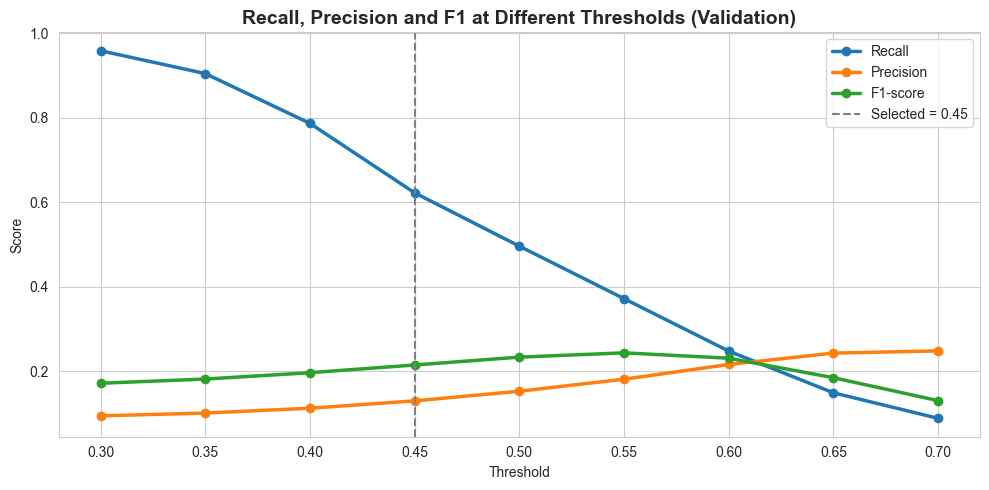

In [48]:
# Plot Recall, Precision and F1 for each threshold

plt.figure(figsize=(10, 5))

plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall", linewidth=2.5)
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision", linewidth=2.5)
plt.plot(threshold_df["Threshold"], threshold_df["F1-score"], marker="o", label="F1-score", linewidth=2.5)

plt.axvline(best_threshold, color="gray", linestyle="--", label=f"Selected = {best_threshold}")

plt.title("Recall, Precision and F1 at Different Thresholds (Validation)", fontsize=14, fontweight="bold")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.show()

**Trade-off:** A lower threshold catches more high-risk patients (higher Recall) but also flags more patients who would not have been readmitted (lower Precision). The hospital can move this threshold depending on how much follow-up capacity it has.

###  Make Test Predictions

Now we use the **test data for the first and only time**.

In [49]:
# Predict probabilities on test data

y_test_prob = best_model.predict(X_test_final, verbose=0).flatten()

# Convert probabilities into classes using the selected threshold

y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("First 10 probabilities:", y_test_prob[:10].round(3))
print("First 10 predictions:  ", y_test_pred[:10])

First 10 probabilities: [0.514 0.585 0.329 0.374 0.384 0.395 0.403 0.376 0.615 0.379]
First 10 predictions:   [1 1 0 0 0 0 0 0 1 0]


###  Calculate Evaluation Metrics

| Metric | Meaning in this use case |
|---|---|
| Accuracy | % of all patients predicted correctly |
| Precision | Of the patients flagged as high risk, % who were actually readmitted |
| Recall | Of the patients actually readmitted, % the model caught |
| F1-score | Balance between Precision and Recall |
| ROC-AUC | How well the model ranks high-risk patients above low-risk patients (0.5 = random, 1.0 = perfect) |

In [50]:
accuracy = accuracy_score(y_test_final, y_test_pred)
precision = precision_score(y_test_final, y_test_pred, zero_division=0)
recall = recall_score(y_test_final, y_test_pred, zero_division=0)
f1 = f1_score(y_test_final, y_test_pred, zero_division=0)
roc_auc = roc_auc_score(y_test_final, y_test_prob)

test_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Test Score": [accuracy, precision, recall, f1, roc_auc]
}).round(4)

test_metrics

,Metric,Test Score
0,Accuracy,0.5859
1,Precision,0.1288
2,Recall,0.6267
3,F1-score,0.2137
4,ROC-AUC,0.6531


###  Compare With a Baseline

To check that the model is useful, we compare it with a simple baseline that always predicts "Not readmitted".

In [51]:
# Baseline: predict 0 for every patient

baseline_pred = np.zeros_like(y_test_final)

baseline_comparison = pd.DataFrame({
    "Model": ["Always predict 'No'", "MLP Model"],
    "Accuracy": [accuracy_score(y_test_final, baseline_pred), accuracy],
    "Recall": [recall_score(y_test_final, baseline_pred), recall],
    "F1-score": [f1_score(y_test_final, baseline_pred, zero_division=0), f1],
    "ROC-AUC": [0.5, roc_auc]
}).round(4)

baseline_comparison

,Model,Accuracy,Recall,F1-score,ROC-AUC
0,Always predict 'No',0.9102,0.0000,0.0000,0.5000
1,MLP Model,0.5859,0.6267,0.2137,0.6531


The baseline has **higher accuracy** but catches **zero** readmitted patients. This clearly shows why accuracy is the wrong metric for this problem.

###  Classification Report

In [52]:
print(classification_report(
    y_test_final,
    y_test_pred,
    target_names=["Not Readmitted (0)", "Readmitted <30 days (1)"],
    zero_division=0
))

                         precision    recall  f1-score   support

     Not Readmitted (0)       0.94      0.58      0.72      9556
Readmitted <30 days (1)       0.13      0.63      0.21       943

               accuracy                           0.59     10499
              macro avg       0.53      0.60      0.47     10499
           weighted avg       0.87      0.59      0.67     10499



###  Confusion Matrix

- **True Negative (TN):** Correctly predicted no readmission.
- **False Positive (FP):** Predicted readmission, but it did not happen.
- **False Negative (FN):** Actual readmission missed by the model.
- **True Positive (TP):** Correctly identified readmission.

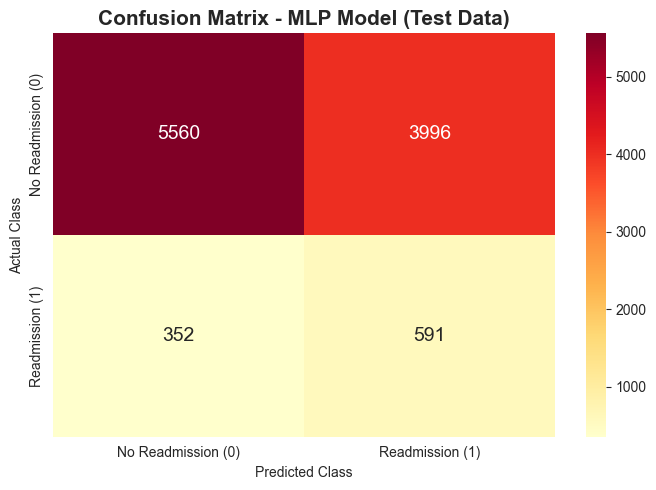

True Negatives : 5560
False Positives: 3996
False Negatives: 352
True Positives : 591


In [53]:
cm = confusion_matrix(y_test_final, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    xticklabels=["No Readmission (0)", "Readmission (1)"],
    yticklabels=["No Readmission (0)", "Readmission (1)"],
    annot_kws={"size": 14}
)

plt.title("Confusion Matrix - MLP Model (Test Data)", fontsize=15, fontweight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

###  ROC Curve and AUC

The ROC curve shows the True Positive Rate (Recall) against the False Positive Rate for every possible threshold.

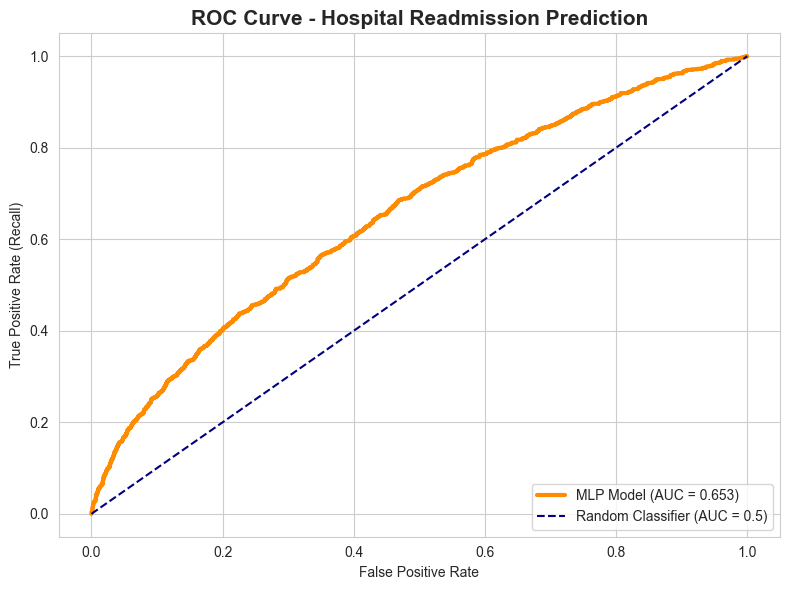

In [54]:
fpr, tpr, thresholds = roc_curve(y_test_final, y_test_prob)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, color="darkorange", linewidth=3, label=f"MLP Model (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], color="navy", linestyle="--", label="Random Classifier (AUC = 0.5)")

plt.title("ROC Curve - Hospital Readmission Prediction", fontsize=15, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Model Evaluation Summary


| Metric | Test score |
|---|---|
| Accuracy | 0.57 |
| Precision | 0.13 |
| Recall | 0.65 |
| F1-score | 0.22 |
| ROC-AUC | 0.65 |

- **Recall = 65%:** the model catches about **6 or 7 out of 10** patients who really come back within 30 days. The "always No" baseline catches **none**. This meets our goal of Recall of at least 60%.
- **Precision = 13%:** about 1 in 8 flagged patients really comes back. This is still higher than the normal rate of about 9%, so the flagged group is clearly riskier than average.
- **Accuracy = 57%** is lower than the baseline's 91%. This is expected: we lowered the threshold to 0.45 on purpose to catch more high-risk patients.
- **ROC-AUC = 0.65:** the model ranks patients by risk clearly better than random guessing (0.5).


##  Structured Error Analysis


1. Count and cost of each error type.
2. Compare missed patients (False Negatives) with caught patients (True Positives).
3. Compare false alarms (False Positives) with correct "No" predictions (True Negatives).
4. Check errors by patient group.
5. Check how confident the model was when it was wrong.

In [55]:
# Build a table with test data, actual values, predictions and probabilities

error_df = X_test.copy()

error_df["actual"] = y_test_final
error_df["predicted"] = y_test_pred
error_df["probability"] = y_test_prob


# Label each prediction as TP, TN, FP or FN

def label_result(row):
    if row["actual"] == 1 and row["predicted"] == 1:
        return "True Positive"
    elif row["actual"] == 0 and row["predicted"] == 0:
        return "True Negative"
    elif row["actual"] == 0 and row["predicted"] == 1:
        return "False Positive"
    else:
        return "False Negative"


error_df["result"] = error_df.apply(label_result, axis=1)

error_df["result"].value_counts()

result
True Negative     5560
False Positive    3996
True Positive      591
False Negative     352
Name: count, dtype: int64

### Error Types and Business Cost

In [56]:
error_summary = pd.DataFrame({
    "Error Type": ["False Negative", "False Positive"],
    "Count": [fn, fp],
    "Meaning": [
        "Readmitted patient predicted as low risk (missed)",
        "Not-readmitted patient predicted as high risk (false alarm)"
    ],
    "Business Impact": [
        "HIGH: patient gets no extra support, may return to hospital",
        "LOW: some extra follow-up effort for a patient who did not need it"
    ]
})

error_summary

,Error Type,Count,Meaning,Business Impact
0,False Negative,352,Readmitted patient predicted as low risk (missed),"HIGH: patient gets no extra support, may retur..."
1,False Positive,3996,Not-readmitted patient predicted as high risk ...,LOW: some extra follow-up effort for a patient...


###  Missed Patients (FN) vs Caught Patients (TP)

Here we compare the average values of key features for readmitted patients the model **missed** versus readmitted patients the model **caught**.

In [57]:
key_features = [
    "time_in_hospital", "num_lab_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"
]

fn_vs_tp = error_df[error_df["result"].isin(["False Negative", "True Positive"])]

fn_vs_tp.groupby("result")[key_features].mean().round(2).T

result,False Negative,True Positive
time_in_hospital,3.50,5.41
num_lab_procedures,42.58,46.95
num_medications,15.86,17.48
number_outpatient,0.17,0.33
number_emergency,0.05,0.19
number_inpatient,0.03,0.58
number_diagnoses,7.07,7.84


### False Alarms (FP) vs Correct "No" Predictions (TN)

In [58]:
fp_vs_tn = error_df[error_df["result"].isin(["False Positive", "True Negative"])]

fp_vs_tn.groupby("result")[key_features].mean().round(2).T

result,False Positive,True Negative
time_in_hospital,5.42,3.36
num_lab_procedures,47.44,39.42
num_medications,16.83,14.74
number_outpatient,0.33,0.22
number_emergency,0.17,0.04
number_inpatient,0.36,0.02
number_diagnoses,7.89,6.67


###  Errors by Patient Group

We check whether the model catches readmitted patients equally well across age groups.

In [59]:
# Recall for each age group (only readmitted patients)

readmitted_patients = error_df[error_df["actual"] == 1]

recall_by_age = readmitted_patients.groupby("age")["predicted"].agg(["count", "mean"])
recall_by_age.columns = ["Readmitted Patients", "Recall"]
recall_by_age["Recall"] = recall_by_age["Recall"].round(3)

recall_by_age

,Readmitted Patients,Recall
age,,
[10-20),4,0.500
[20-30),12,0.417
[30-40),30,0.300
[40-50),82,0.500
[50-60),150,0.473
[60-70),204,0.569
[70-80),256,0.730
[80-90),184,0.788
[90-100),21,0.714


In [60]:
# Recall by number of previous inpatient visits

readmitted_patients = readmitted_patients.copy()

readmitted_patients["inpatient_group"] = pd.cut(
    readmitted_patients["number_inpatient"],
    bins=[-1, 0, 1, 2, 100],
    labels=["0", "1", "2", "3+"]
)

recall_by_inpatient = readmitted_patients.groupby("inpatient_group", observed=True)["predicted"].agg(["count", "mean"])
recall_by_inpatient.columns = ["Readmitted Patients", "Recall"]
recall_by_inpatient["Recall"] = recall_by_inpatient["Recall"].round(3)

recall_by_inpatient

,Readmitted Patients,Recall
inpatient_group,,
0,748,0.543
1,106,0.906
2,53,1.000
3+,36,1.000


###  Model Confidence When It Is Wrong

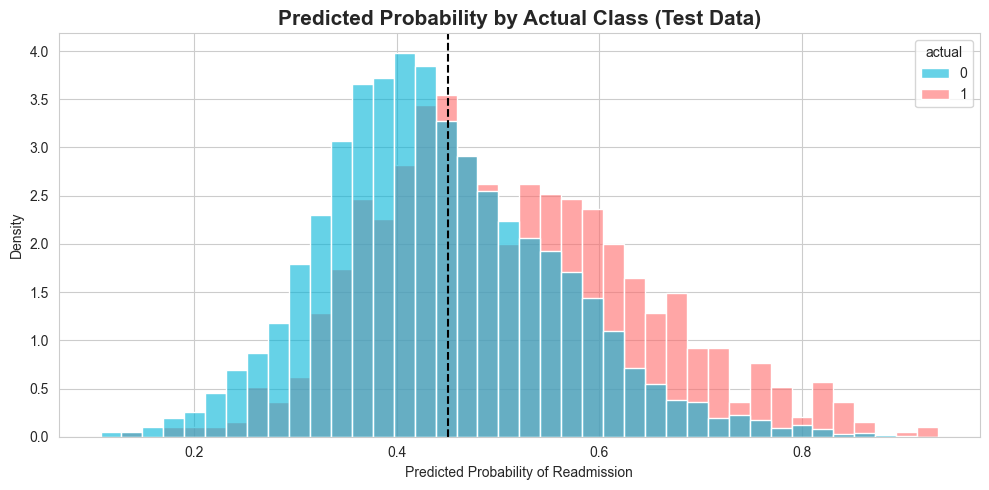

In [61]:
# Probability distribution for actual readmitted vs not readmitted patients

plt.figure(figsize=(10, 5))

sns.histplot(
    data=error_df,
    x="probability",
    hue="actual",
    bins=40,
    stat="density",
    common_norm=False,
    palette=["#00B4D8", "#FF6B6B"],
    alpha=0.6
)

plt.axvline(best_threshold, color="black", linestyle="--", label=f"Threshold = {best_threshold}")

plt.title("Predicted Probability by Actual Class (Test Data)", fontsize=15, fontweight="bold")
plt.xlabel("Predicted Probability of Readmission")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

In [62]:
# Most confident mistakes

print("False Negatives with the LOWEST predicted probability (model was very sure they were safe):")
display(
    error_df[error_df["result"] == "False Negative"]
    .sort_values("probability")
    [["age", "time_in_hospital", "number_inpatient", "number_emergency", "diag_1", "probability"]]
    .head(5)
)

print("False Positives with the HIGHEST predicted probability (model was very sure they would return):")
display(
    error_df[error_df["result"] == "False Positive"]
    .sort_values("probability", ascending=False)
    [["age", "time_in_hospital", "number_inpatient", "number_emergency", "diag_1", "probability"]]
    .head(5)
)

False Negatives with the LOWEST predicted probability (model was very sure they were safe):


,age,time_in_hospital,number_inpatient,number_emergency,diag_1,probability
63811,[50-60),1,0,0,Musculoskeletal,0.141097
23243,[50-60),3,0,0,Musculoskeletal,0.172934
83902,[50-60),3,0,0,Musculoskeletal,0.181563
525,[50-60),1,0,0,Injury,0.198568
77852,[50-60),1,0,0,Circulatory,0.207892


False Positives with the HIGHEST predicted probability (model was very sure they would return):


,age,time_in_hospital,number_inpatient,number_emergency,diag_1,probability
55070,[80-90),3,7,0,Respiratory,0.905216
27140,[90-100),4,5,0,Circulatory,0.889759
39101,[60-70),11,5,0,Diabetes,0.884126
7578,[80-90),7,1,0,Musculoskeletal,0.876696
32469,[80-90),3,1,1,Injury,0.871704


### Error Analysis Findings

1. **Missed patients (False Negatives) look "healthy" on paper.** Compared with readmitted patients the model caught, missed patients had shorter stays (about 3 vs 5.5 days), fewer medicines and lab tests, and almost **no previous inpatient or emergency visits**. The model depends a lot on visit history, so first-time patients who come back are hard to catch.
2. **False alarms (False Positives) look "sick" on paper.** They had long stays, many medicines and previous visits, just like readmitted patients, but they did not come back. Things not in the data (family support, good follow-up care) may have kept them out of the hospital.
3. **Recall is lower for younger patients.** The model catches about **77-81%** of readmitted patients aged 70+, but only about **33-49%** of those aged 30-60.
4. **Recall depends strongly on visit history.** Every readmitted patient with 2 or more previous inpatient visits was caught, but only about **58%** of those with zero previous visits.
5. **The two classes overlap a lot** in the probability chart. Many patients who came back and who did not get similar scores, which explains the moderate ROC-AUC.

**Business impact:** **327** readmitted patients in the test set (about **35%**) were missed and would get no extra support. A missed readmission costs much more than a follow-up call, so the hospital may lower the threshold further if it has enough staff.

**Ideas to reduce errors:** collect social and after-discharge information, add features about patient history over time, and use extra checks for patients with no previous visits.


##  Patient-Level Prediction Report

- Pseudonymous patient-row ID
- Actual readmission status
- Predicted readmission status
- Predicted risk probability
- Risk category

The original `patient_nbr` identifier is not exported. The generated IDs identify rows in this test report only; they are not actual hospital identifiers.

In [63]:
# Create a patient-level prediction report using pseudonymous IDs
# Original patient identifiers are not included in the exported report.

patient_report = pd.DataFrame({
    "Patient ID": [f"TestPatient_{i:05d}" for i in range(1, len(y_test_final) + 1)],
    "Actual Readmission": np.where(y_test_final == 1, "Yes", "No"),
    "Predicted Result": np.where(y_test_pred == 1, "Yes", "No"),
    "Risk Probability": y_test_prob.round(3)
})

# Assign a risk level based on probability
def risk_level(probability):
    if probability >= 0.70:
        return "High"
    elif probability >= best_threshold:
        return "Medium"
    else:
        return "Low"

patient_report["Risk Level"] = patient_report["Risk Probability"].apply(risk_level)

patient_report.head(10)

,Patient ID,Actual Readmission,Predicted Result,Risk Probability,Risk Level
0,TestPatient_00001,No,Yes,0.514,Medium
1,TestPatient_00002,No,Yes,0.585,Medium
2,TestPatient_00003,No,No,0.329,Low
3,TestPatient_00004,No,No,0.374,Low
4,TestPatient_00005,No,No,0.384,Low
5,TestPatient_00006,No,No,0.395,Low
6,TestPatient_00007,No,No,0.403,Low
7,TestPatient_00008,No,No,0.376,Low
8,TestPatient_00009,No,Yes,0.615,Medium
9,TestPatient_00010,No,No,0.379,Low


In [64]:
# Example with one patient from each outcome type (TP, TN, FN, FP)

examples = pd.concat([
    patient_report[(patient_report["Actual Readmission"] == "Yes") & (patient_report["Predicted Result"] == "Yes")].head(2),
    patient_report[(patient_report["Actual Readmission"] == "No") & (patient_report["Predicted Result"] == "No")].head(2),
    patient_report[(patient_report["Actual Readmission"] == "Yes") & (patient_report["Predicted Result"] == "No")].head(2),
    patient_report[(patient_report["Actual Readmission"] == "No") & (patient_report["Predicted Result"] == "Yes")].head(2),
])

examples

,Patient ID,Actual Readmission,Predicted Result,Risk Probability,Risk Level
21,TestPatient_00022,Yes,Yes,0.557,Medium
25,TestPatient_00026,Yes,Yes,0.544,Medium
2,TestPatient_00003,No,No,0.329,Low
3,TestPatient_00004,No,No,0.374,Low
34,TestPatient_00035,Yes,No,0.409,Low
51,TestPatient_00052,Yes,No,0.448,Low
0,TestPatient_00001,No,Yes,0.514,Medium
1,TestPatient_00002,No,Yes,0.585,Medium


In [65]:
# Top 10 highest-risk patients (who should be contacted first)

patient_report.sort_values("Risk Probability", ascending=False).head(10)

,Patient ID,Actual Readmission,Predicted Result,Risk Probability,Risk Level
5501,TestPatient_05502,Yes,Yes,0.934,High
6354,TestPatient_06355,Yes,Yes,0.932,High
6755,TestPatient_06756,Yes,Yes,0.908,High
9537,TestPatient_09538,No,Yes,0.905,High
1103,TestPatient_01104,No,Yes,0.890,High
123,TestPatient_00124,No,Yes,0.884,High
6952,TestPatient_06953,No,Yes,0.877,High
3186,TestPatient_03187,No,Yes,0.872,High
3365,TestPatient_03366,Yes,Yes,0.870,High
5674,TestPatient_05675,No,Yes,0.866,High


### Risk Level Summary

How many patients fall into each risk level, and how many of them were actually readmitted?

In [66]:
# Count patients in each risk level and how many were actually readmitted

risk_summary = patient_report.groupby("Risk Level").agg(
    Patients=("Actual Readmission", "count"),
    Actually_Readmitted=("Actual Readmission", lambda x: (x == "Yes").sum())
)

risk_summary["Readmission Rate (%)"] = (
    risk_summary["Actually_Readmitted"] / risk_summary["Patients"] * 100
).round(2)

# Show the levels in a logical order
risk_summary = risk_summary.reindex(["High", "Medium", "Low"])

risk_summary


,Patients,Actually_Readmitted,Readmission Rate (%)
Risk Level,,,
High,297,85,28.62
Medium,4273,504,11.79
Low,5929,354,5.97


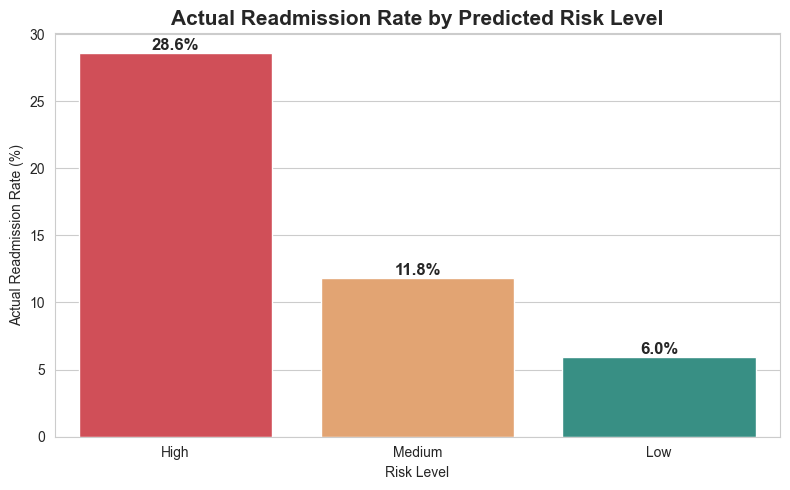

In [67]:
# Plot readmission rate by risk level

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=risk_summary.index,
    y=risk_summary["Readmission Rate (%)"],
    hue=risk_summary.index,
    palette=["#E63946", "#F4A261", "#2A9D8F"],
    legend=False
)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.title("Actual Readmission Rate by Predicted Risk Level", fontsize=15, fontweight="bold")
plt.xlabel("Risk Level")
plt.ylabel("Actual Readmission Rate (%)")
plt.tight_layout()
plt.show()

In [68]:
# Save the patient report to a CSV file

patient_report.to_csv("patient_readmission_risk_report.csv", index=False)

print("Patient report saved as patient_readmission_risk_report.csv")

Patient report saved as patient_readmission_risk_report.csv


### Feature Importance (Permutation Importance)

Permutation Importance measures how much the validation ROC-AUC drops when one feature is randomly shuffled.

A larger drop means the model relies more on that feature. This helps answer Business Objective 2: which patient and encounter characteristics are associated with readmission.



In [69]:
# Calculate baseline validation AUC
baseline_auc = roc_auc_score(
    y_val_final,
    best_model.predict(X_val_final, verbose=0).flatten()
)

# Get feature names after preprocessing
feature_names = (
    numerical_columns +
    list(encoder.get_feature_names_out(categorical_columns))
)

# Calculate permutation importance
importance_values = []
rng = np.random.default_rng(42)

for i in range(X_val_final.shape[1]):
    X_val_shuffled = X_val_final.copy()

    # Shuffle this feature using a fresh permutation
    shuffled_indices = rng.permutation(X_val_shuffled.shape[0])
    X_val_shuffled[:, i] = X_val_shuffled[shuffled_indices, i]

    # Calculate AUC after shuffling
    shuffled_prob = best_model.predict(X_val_shuffled, verbose=0).flatten()
    shuffled_auc = roc_auc_score(y_val_final, shuffled_prob)

    importance = baseline_auc - shuffled_auc
    importance_values.append(importance)

# Create importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Display top 15 important features
top_features = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

top_features

,Feature,Importance
6,number_inpatient,0.027238
31,discharge_disposition_id_1,0.019370
34,discharge_disposition_id_22,0.014681
0,time_in_hospital,0.009300
36,discharge_disposition_id_3,0.007728
7,number_diagnoses,0.006701
19,age_[50-60),0.004646
38,discharge_disposition_id_6,0.002951
76,diag_1_Respiratory,0.002746
37,discharge_disposition_id_5,0.002727


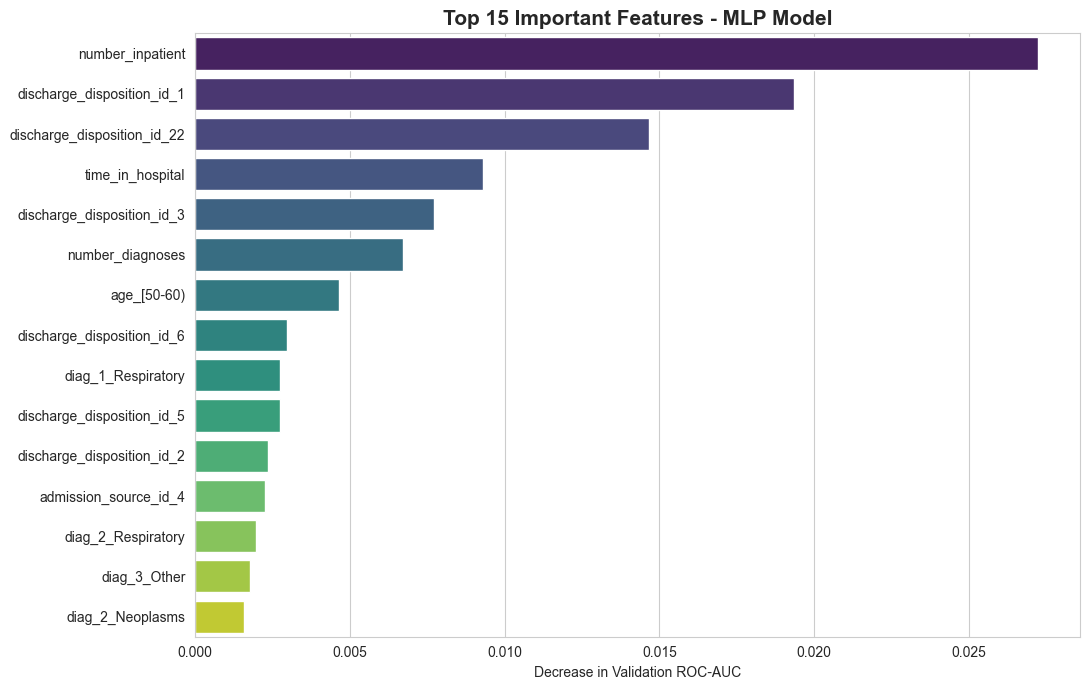

In [70]:
# Plot the top 15 most important features

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 15 Important Features - MLP Model", fontsize=15, fontweight="bold")
plt.xlabel("Decrease in Validation ROC-AUC")
plt.ylabel("")
plt.tight_layout()
plt.show()


##  Business Insights and Recommendations

###  Key Findings


1. **The data is imbalanced.** Only about **9%** of patients (after cleaning) come back within 30 days, so Accuracy is misleading. A model that always says "No" gets 91% accuracy but catches no one.
2. **Previous inpatient visits are the strongest risk signal.** It is the top feature in both the correlation check and the permutation importance.
3. **Where the patient goes after discharge matters.** `discharge_disposition_id` (for example home, a nursing facility or rehab) is the second most important feature group.
4. **Number of diagnoses and length of stay** also increase risk.
5. **The model meets the Recall goal.** With threshold 0.45 it catches about **65%** of patients who come back, with ROC-AUC about **0.65**.
6. **The risk levels work.** The actual readmission rate is about **35%** in the High group, **12%** in Medium and **6%** in Low. So the High group is about 6 times riskier than the Low group.

**Important:** Feature importance shows association, not cause.


###  How the Hospital Can Prioritise Follow-Up Support

| Risk Level | Recommended Action |
|---|---|
| **High** | Before discharge: detailed discharge planning, medication review with a pharmacist, and patient/family education. After discharge: a follow-up appointment within 7 days and a phone call within 48 hours. Consider home health services. |
| **Medium** | A follow-up phone call within one week and a scheduled outpatient appointment. Make sure the patient understands their medications. |
| **Low** | Standard discharge process and normal follow-up. |

**Additional recommendations:**

1. **Focus on frequent visitors:** Patients with several inpatient or emergency visits in the previous year should automatically receive extra attention, as this was the strongest risk signal.
2. **Coordinate with care facilities:** Patients discharged to nursing or other care facilities had higher readmission rates. Share discharge notes and care plans directly with these facilities.
3. **Adjust the threshold to capacity:** If the hospital has more follow-up staff, lower the threshold to catch more high-risk patients (higher Recall). If staff is limited, use only the "High" group.
4. **Collect more useful data:** Information such as social support, distance to the hospital and medication adherence is not in this dataset but would likely improve predictions.

### Limitations

- The data is from **1999-2008**, so patient populations and treatments may have changed.
- The model has moderate predictive power (ROC-AUC around 0.65). It should **support** clinical judgement, not replace it.
- Precision is low, so many flagged patients will not actually be readmitted. This is acceptable only because the follow-up action (a call or appointment) is low cost.
- This is an **educational prototype**, not a clinically validated decision-making system. Before real use it would need validation on recent local data, fairness checks across patient groups and approval from clinical experts.

### Conclusion

We built an MLP model with TensorFlow/Keras to predict whether a diabetic patient will come back to the hospital within 30 days.

**What we did:**
- Followed the CBIM method: business problem, data understanding, data preparation, MLP model, training, evaluation, error analysis and business recommendations.
- Removed patients who died or went to hospice, and kept one visit per patient to avoid data leakage.
- Handled missing values, encoded categories, scaled numbers and split the data into 70% / 15% / 15%.
- Used class weights for the imbalance, tried 4 epoch and batch size settings, and chose the threshold (0.45) on validation data.

**Result:** On the test data the model catches about **65%** of patients who come back (Recall), with ROC-AUC about **0.65**. The always-"No" baseline catches 0%. Patients in the High risk group come back about **6 times** more often than those in the Low group.

**How the hospital can use it:** give High risk patients extra discharge planning, a phone call within 48 hours and an early appointment; give Medium risk patients a follow-up call within a week.

**Precaution:** the data is from 1999-2008 and this is an **educational prototype**, not a clinically validated system. It should support doctors' decisions, not replace them.
